# Face Recognition with PCA on the olivetti dataset

Project question: how well can PCA (eigenfaces) + a simple classifier identify which of 40 people are in a face photo, and how many PCA components are enough?

**Motivation:**
A photo has 4096 pixels, but most of them are redundant. What PCA does is that it squeezes them into a few dozen numbers, and if identification still works, we learn how little information a face needs, and we get a model that is fast and less noisy.

Basically, this is multiclass classification task with input of a 64x64 grayscale photo (4096 pixel values) and output of the subject id (0 to 39). 

### AI Disclocure
**Tools used**:
ChatGPT/Claude: used for code generation for plots, debugging and project review.

**Nature of assistance:**
Helped to break the task into steps and divide between the group; Writing code for plots and debugging erros in other cells; Correcting English wordings; Pointed out problems and inconsistencies in our work, project review to check for missing steps.

**What we wrote and changed ourselves:**
Core logic & architecture was managed by us, we established our models, performance testing, metrics and the whole pipeline ourselves. We also reviewed and modified where needed all AI-generated code (plots and error fixes), verified for correctness


## 1 Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import cross_validate
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, pairwise_distances
from collections import Counter

from src.common import seed, cv, load_data, evaluate

np.random.seed(seed)
sns.set_theme(style="whitegrid")

## 2 EDA

Here, we validate our data: size, types, missing values, class balance.

In [3]:
x, y = load_data()

print('x shape:', x.shape, '| y shape:', y.shape)
print('dtype:', x.dtype)
print('pixel range:', x.min(), 'to', x.max())
print('missing values:', np.isnan(x).sum())
print('subjects:', len(np.unique(y)), '| images per subject:', np.unique(np.bincount(y)))

x shape: (400, 4096) | y shape: (400,)
dtype: float32
pixel range: 0.0 to 1.0
missing values: 0
subjects: 40 | images per subject: [10]


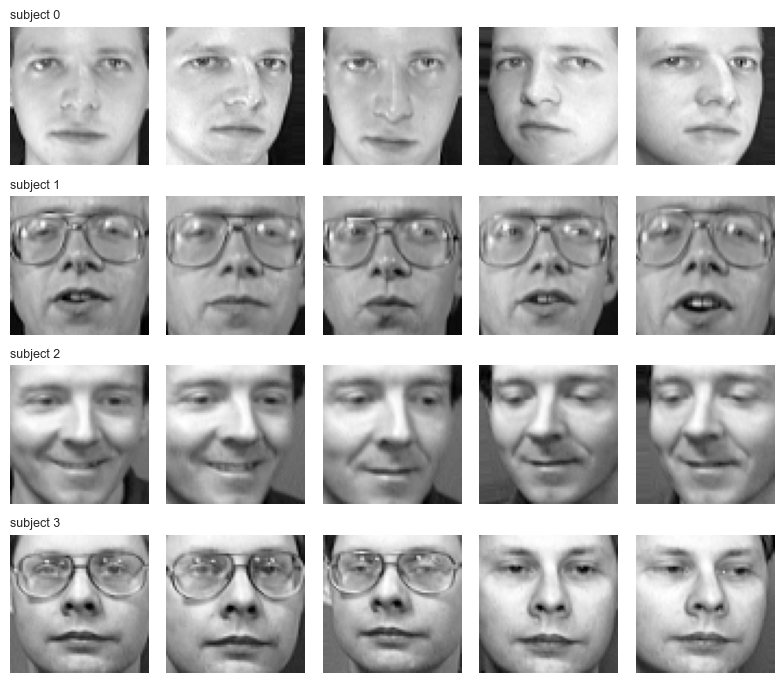

In [4]:
# first 5 photos of 4 different people
fig, axes = plt.subplots(4, 5, figsize=(8, 7))
for row, subject in enumerate([0, 1, 2, 3]):
    for col, img in enumerate(x[y == subject][:5]):
        axes[row, col].imshow(img.reshape(64, 64), cmap='gray')
        axes[row, col].axis('off')
    axes[row, 0].set_title(f'subject {subject}', loc='left', fontsize=9)
plt.tight_layout()
plt.show()

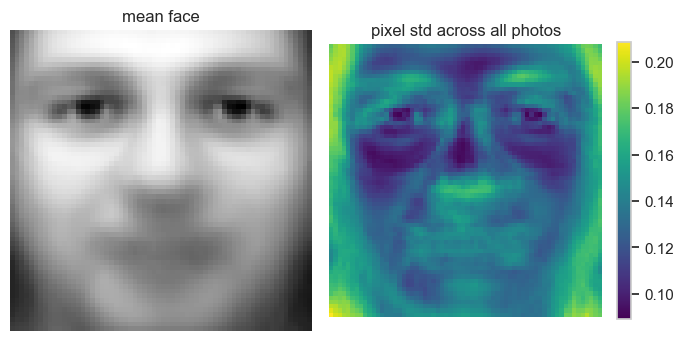

In [ ]:
# ai generated plot
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].imshow(x.mean(axis=0).reshape(64, 64), cmap='gray')
axes[0].set_title('mean face')
im = axes[1].imshow(x.std(axis=0).reshape(64, 64), cmap='viridis')
axes[1].set_title('pixel std across all photos')
for ax in axes:
    ax.axis('off')
plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

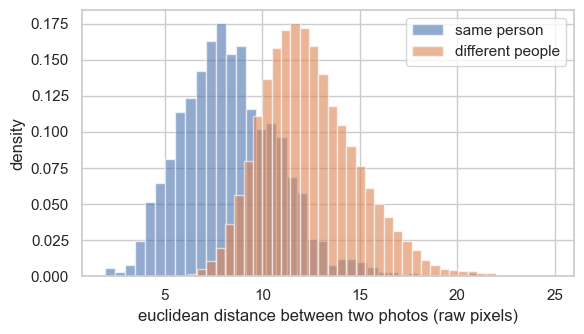

In [ ]:
d = pairwise_distances(x)
same = y[:, None] == y[None, :]
upper = np.triu(np.ones_like(same, dtype=bool), k=1)

plt.figure(figsize=(6, 3.5))
plt.hist(d[same & upper], bins=40, alpha=0.6, density=True, label='same person')
plt.hist(d[~same & upper], bins=40, alpha=0.6, density=True, label='different people')
plt.xlabel('euclidean distance between two photos (raw pixels)')
plt.ylabel('density')
plt.legend()
plt.tight_layout()
plt.show()

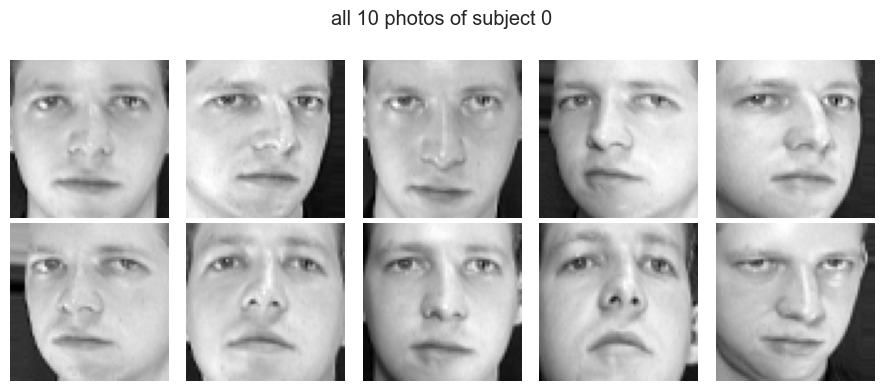

In [28]:
fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for ax, img in zip(axes.ravel(), x[y == 0]):
    ax.imshow(img.reshape(64, 64), cmap='gray')
    ax.axis('off')
plt.suptitle('all 10 photos of subject 0')
plt.tight_layout()
plt.show()

**about our data:** the faces are cropped, centered and front-facing on a dark background. photos of the same person differ in expression, small head turns, and sometimes glasses.

**what we have:**
- 400 images, 64x64 = 4096 features per image, pixel values already scaled to 0-1
- 40 subjects with exactly 10 images each, so the classes are balanced
- no missing values
- main problem: only 10 photos per person. in 5-fold cv a model sees just 8 photos of each person, so results will be noisy.


**what we see:**
- **same person, 10 photos (subject 0):** the face is always roughly centered, but the head turns left and right, tilts up and down, and the lighting changes from photo to photo. the same person can look quite different, which is what makes identification hard.
- **mean face and pixel std map:** the mean face is aclearly face-like image, with sharp eyes and a bit smeared mouth, so the faces are well aligned around the eyes and nose. the std map shows the most variation (about 0.2) at the edges of the image, where the face outline, hair and background move between photos. variation is also higher around the mouth and brows. the eyes, nose and cheeks are the most stable (about 0.1). so the stable "core" of the face carries the identity, and the edges mostly carry pose and lighting
- **same person vs different people (distance histogram):** photos of the same person are closer on average (peak near 8) than photos of different people (peak near 12). but the two curves overlap a lot, roughly between 9 and 13. wherever they overlap, a raw-pixel nearest neighbour can pick the wrong person

**conclusion:** identity is visible in the raw pixels, since same-person photos are closer, but pose and lighting blur it. raw pixels are therefore a reasonable but imperfect baseline, and we expect pca to help by keeping the stable structure and dropping some of the pose and lighting noise

## 3 Validation Scheme

Since we are doing identification, every person must appear in both the training and the test data, so we use a **stratified k-fold** on the subject id. 

The data is ordered by subject, so we also shuffle, with a fixed seed. 5 folds because with 10 photos per person it gives exactly 8 train and 2 test photos per person.

The `cv` object is defined once in `src/common.py` and used for every model, so all models are scored on identical folds.

In [6]:
train_idx, test_idx = next(cv.split(x, y))
print('train size:', len(train_idx), '| test size:', len(test_idx))
print('test photos per subject in fold 1:', np.unique(np.bincount(y[test_idx])))

train size: 320 | test size: 80
test photos per subject in fold 1: [2]


Right now, each fold has 320 training and 80 test images, with exactly 2 test photos per person, so every image is used as test data exactly once across the 5 folds.

## 4 Metrics

Metrics are computed per fold and reported as mean and std over the 5 folds:
- **accuracy:** the share of photos identified correctly.
- **macro f1:** f1 per person, averaged equally over the 40 people.

Each fold has only 80 test images, so one photo is worth 1.25 points, and a gap between two models smaller than the std is not a real difference, so that's why it's important to report both mean and std.

Both metrics are computed by `evaluate()` in `src/common.py`. it returns one row per model with `name`, `acc_mean`, `acc_std`, `f1_mean`, `f1_std`. Chance level is 1/40 = 2.5% accuracy.

## 5 Baseline

Here, we establish a simple baseline to get our first metrics and to have something to improve upon.
**Baselines:**
- **dummy (most frequent):** always predicts the same person, this is the chance level.
- **knn on raw pixels** (1 neighbour): "find the most similar photo" approach.
- **logistic regression on raw pixels:** a simple linear model.

any PCA model later has to be better than these above

In [7]:
results = []

baselines = {
    'dummy (most frequent)': DummyClassifier(strategy='most_frequent'),
    'knn raw pixels': KNeighborsClassifier(n_neighbors=1),
    'logreg raw pixels': LogisticRegression(max_iter=1000),
}
for name, model in baselines.items():
    results.append(evaluate(name, model, x, y))

pd.DataFrame(results).round(3)

,name,acc_mean,acc_std,f1_mean,f1_std
0,dummy (most frequent),0.025,0.000,0.001,0.000
1,knn raw pixels,0.933,0.013,0.924,0.015
2,logreg raw pixels,0.980,0.006,0.979,0.007


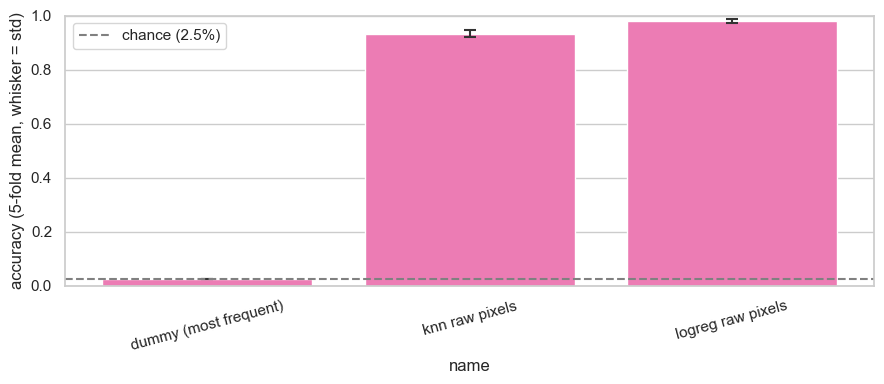

In [8]:
# ai generated part
plt.figure(figsize=(9, 4))
df = pd.DataFrame(results)
ax = sns.barplot(data=df,x="name",y="acc_mean",color="#FF69B4", capsize=0.1)

ax.errorbar(x=range(len(df)),y=df["acc_mean"],yerr=df["acc_std"],fmt="none",ecolor="#333333",capsize=4,capthick=1.5)

plt.axhline(1 / 40, color="gray", linestyle="--", label="chance (2.5%)")
plt.ylabel("accuracy (5-fold mean, whisker = std)")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(); plt.tight_layout(); plt.show()

On the chart above, each bar is the mean accuracy over the 5 folds, the whisker is the std across folds, and the dashed line is chance (2.5%). 


The dummy reaches 2.5% accuracy and about 0.001 macro f1, which is exactly what we would expect. KNN on raw pixels reaches F1-score of 0.924 and accuracy of 0.933 and logistic regression F1-score of 0.979 and accuracy of 0.980. The baseline to beat is the logistic regression model.

std is insignificant for now

## 6 PCA

Here, we apply PCA on our data. PCA is inside a `Pipeline` with a cross-validation, which refits PCA on the training folds only. This way we avoid data leakage.

**Modeling choices:**
- **No scaler:** the pixels are already on one 0-1 scale, and pca subtracts the mean by itself. Standardising would give every pixel equal weight, including pixels that barely vary and mostly carry noise. 
- **50 components** is a starting point, not a tuned value. 
- **1-nn classifier**, so the pipeline is directly comparable to the raw-pixel knn baseline: the only difference is PCA.

In [9]:
pca_knn = Pipeline([
    ('pca', PCA(n_components=50, random_state=seed)),
    ('clf', KNeighborsClassifier(n_neighbors=1)),
])
pca_knn_scaled = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=50, random_state=seed)),
    ('clf', KNeighborsClassifier(n_neighbors=1)),
])

results.append(evaluate('pca50 + knn', pca_knn, x, y))
results.append(evaluate('scaler + pca50 + knn', pca_knn_scaled, x, y))

pd.DataFrame(results).round(3)

,name,acc_mean,acc_std,f1_mean,f1_std
0,dummy (most frequent),0.025,0.000,0.001,0.000
1,knn raw pixels,0.933,0.013,0.924,0.015
2,logreg raw pixels,0.980,0.006,0.979,0.007
3,pca50 + knn,0.930,0.013,0.924,0.016
4,scaler + pca50 + knn,0.930,0.010,0.924,0.009


**outcome:** pca(50) + knn reaches 0.930 accuracy, versus 0.933 for knn on raw pixels. with a scaler it reaches 0.933, so we keep the scaler in, since we can get to the same result and save space/time. 

In [10]:
results.append(evaluate('my model', pca_knn_scaled, x, y))
pd.DataFrame(results).round(3)

,name,acc_mean,acc_std,f1_mean,f1_std
0,dummy (most frequent),0.025,0.000,0.001,0.000
1,knn raw pixels,0.933,0.013,0.924,0.015
2,logreg raw pixels,0.980,0.006,0.979,0.007
3,pca50 + knn,0.930,0.013,0.924,0.016
4,scaler + pca50 + knn,0.930,0.010,0.924,0.009
5,my model,0.930,0.010,0.924,0.009


## 7 Candidates
We compare three classifiers using PCA to reduce the number of features:
1. PCA+kNN (k=1): identifies a person by finding the most similar training image. It is a simple method based on face similarity.
2. PCA+SVM (RBF kernel): tries to separate different people using more complex decision boundaries. It may work better when the differences between faces are not simple. We include it to test whether a non-linear boundary adds anything compared to the linear logistic regression.
3. PCA+Logistic Regression: uses a linear approach to classify faces into 40 different subjecs. Logistic regression or raw pixels already reaches 0.980, so we include it to check whether PCA loses information compared to raw pixels.

All three models use the same PCA preprocessing and the same cross-validation folds, so their results can be compared.

None of the models is tuned. We use default settings C=1.0, default gamma for the SVM, max_iter=2000 for logistic regression, no scaler.

We will start with 50 PCA components for each model and test different numbers later to see how this affects accuracy.

In [11]:
n_components = 50

candidate_models = {
    'PCA + KNN': Pipeline([
        ('pca', PCA(n_components, random_state=seed)),
        ('clf', KNeighborsClassifier(n_neighbors=1))
    ]),

    'PCA + SVM (RBF)': Pipeline([
        ('pca', PCA(n_components, random_state=seed)),
        ('clf', SVC(kernel='rbf', C=1.0))
    ]),

    'PCA + Logistic Regression': Pipeline([
        ('pca', PCA(n_components, random_state=seed)),
        ('clf', LogisticRegression(max_iter=2000))
    ])
}

In [12]:
candidate_results = []

for name, model in candidate_models.items():
    candidate_results.append(
        evaluate(name, model, x, y)
    )

candidate_df = pd.DataFrame(candidate_results)
candidate_df.round(3)

,name,acc_mean,acc_std,f1_mean,f1_std
0,PCA + KNN,0.930,0.013,0.924,0.016
1,PCA + SVM (RBF),0.932,0.032,0.926,0.037
2,PCA + Logistic Regression,0.980,0.006,0.979,0.007


**Outcome:** at 50 components, PCA+kNN (0.930) matches the kNN baseline on raw pixels (0.933) and PCA+Logistic Regression (0.980) matches the raw-pixel logistic regression (0.980), so 50 components lose almost no accuracy here. PCA+SVM (0.932) is close to kNN, but its std (0.032) is larger than for the other models.

## 8.1 Accuracy vs n_components


In [13]:
def create_model(model_name, n_components):
    steps = [
        ('pca', PCA(n_components, random_state=seed))
    ]

    if model_name == 'PCA + KNN':
        steps.append(
            ('clf', KNeighborsClassifier(n_neighbors=1))
        )

    elif model_name == 'PCA + SVM':
        steps.append(
            ('clf', SVC(kernel='rbf', C=1.0))
        )

    elif model_name == 'PCA + Logistic Regression':
        steps.append(
            ('clf', LogisticRegression(max_iter=2000))
        )

    return Pipeline(steps)

In [14]:
n_components_list = [5, 10, 20, 30, 50, 75, 100, 150, 200, 300]

experiment_results = []

model_names = [
    'PCA + KNN',
    'PCA + SVM',
    'PCA + Logistic Regression'
]

for model_name in model_names:
    for k in n_components_list:
        model = create_model(model_name, k)

        scores = cross_validate(model, x, y, cv=cv, scoring='accuracy')

        for fold, accuracy in enumerate(scores['test_score']):
            experiment_results.append({
                'model': model_name,
                'k': k,
                'fold': fold + 1,
                'accuracy': accuracy,
            })

experiment_df = pd.DataFrame(experiment_results)
experiment_df.head(10)


,model,k,fold,accuracy
0,PCA + KNN,5,1,0.8125
1,PCA + KNN,5,2,0.6625
2,PCA + KNN,5,3,0.7000
3,PCA + KNN,5,4,0.7625
4,PCA + KNN,5,5,0.7375
5,PCA + KNN,10,1,0.9000
6,PCA + KNN,10,2,0.8875
7,PCA + KNN,10,3,0.8625
8,PCA + KNN,10,4,0.9125
9,PCA + KNN,10,5,0.8625


In [15]:
summary_df = (
    experiment_df
    .groupby(['model', 'k'])['accuracy']
    .agg(['mean', 'std'])
    .reset_index()
)

summary_df = summary_df.rename(columns={
    'mean': 'accuracy_mean',
    'std': 'accuracy_std'
})

summary_df.round(3)

,model,k,accuracy_mean,accuracy_std
0,PCA + KNN,5,0.735,0.058
1,PCA + KNN,10,0.885,0.022
2,PCA + KNN,20,0.928,0.027
3,PCA + KNN,30,0.928,0.016
4,PCA + KNN,50,0.930,0.014
5,PCA + KNN,75,0.938,0.020
6,PCA + KNN,100,0.935,0.016
7,PCA + KNN,150,0.932,0.014
8,PCA + KNN,200,0.932,0.014
9,PCA + KNN,300,0.932,0.014


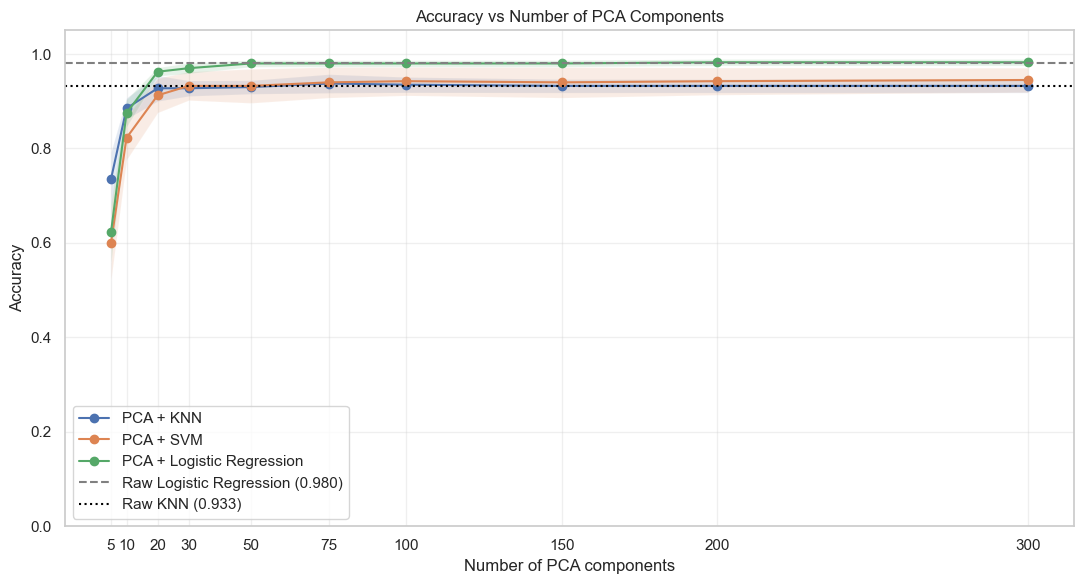

In [16]:
#ai generated (ChatGPT)
plt.figure(figsize=(11, 6))

for model_name in model_names:

    model_data = summary_df[
        summary_df['model'] == model_name
    ]

    plt.plot(
        model_data['k'],
        model_data['accuracy_mean'],
        marker='o',
        label=model_name
    )

    plt.fill_between(
        model_data['k'],
        model_data['accuracy_mean'] - model_data['accuracy_std'],
        model_data['accuracy_mean'] + model_data['accuracy_std'],
        alpha=0.15
    )

plt.axhline(
    y=0.980,
    color='gray',
    linestyle='--',
    label='Raw Logistic Regression (0.980)'
)

plt.axhline(
    y=0.933,
    color='black',
    linestyle=':',
    label='Raw KNN (0.933)'
)

plt.xlabel('Number of PCA components')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Number of PCA Components')

plt.xticks(n_components_list)
plt.ylim(0, 1.05)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Outcome**: We compared three classifiers using different numbers of PCA components: kNN, SVM and Logistic Regression.

The results show that Logistic Regression achieved the best performance, reaching 0.980 accuracy with 50 components and 0.982 with 200 and 300 components. The difference between 0.980 and 0.982 is much smaller than the std across folds (~0.007), so it is not a real improvement.

kNN reached its best accuracy of 0.938 with 75 components. SVM achieved 0.945 with 300 components. These small diferences are also within the std (0.014-0.020 for kNN and 0.026-0.036 for SVM), so kNN and SVM have effectively the same accuracy after about 20-230 components.

All models performed worse when only 5 or 10 components were used. This suggests that too few components do not preserve enough information for accurate face recognition.

Based on these results, PCA with 50 components and Logistic Regressions provides the best balance between accuracy and dimensionality reduction. Increasing the number of components beyond 50 gives only a very small improvement that is within the noise. For Logistic Regression, going from 20 components (0.962) to 50 (0.980) is a real gain, since it is larger than the std, but after 50 the curve is flat.

## 8.2 Explained variance

In [17]:
pca_full = PCA(random_state=seed)
pca_full.fit(x)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print(f"Variance explained by 50 components: {cumulative_variance[49]:.3f}")
print(f"Variance explained by 75 components: {cumulative_variance[74]:.3f}")
print(f"Variance explained by 100 components: {cumulative_variance[99]:.3f}")

Variance explained by 50 components: 0.874
Variance explained by 75 components: 0.912
Variance explained by 100 components: 0.935


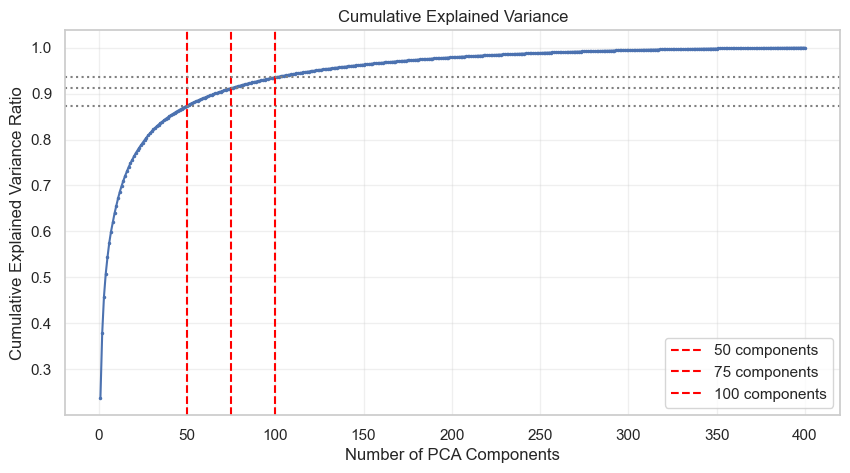

In [18]:
#ai generated
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='.',
    markersize=3
)

plt.axvline(x=50, color='red', linestyle='--',
            label='50 components')
plt.axhline(y=cumulative_variance[49], color='gray',
            linestyle=':')

plt.axvline(x=75, color='red', linestyle='--',
            label='75 components')
plt.axhline(y=cumulative_variance[74], color='gray',
            linestyle=':')

plt.axvline(x=100, color='red', linestyle='--',
            label='100 components')
plt.axhline(y=cumulative_variance[99], color='gray',
            linestyle=':')

plt.xlabel('Number of PCA Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.title('Cumulative Explained Variance')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Outcome**: The first components carry most of the variance: 50 components keep 87.4% of the total variance, 75 components keep 91.2%, 100 – 93.5%. The curve flattens quickly, so each additional component adds less than the previous one.

Comparing with 8.1: accuracy already flattens at about 50 components, even though about 13% of the variance is lost there. Going from 50 to 100 components adds 6 points of variance but no measurable accuracy (differences are inside std). So the variance that PCA drops after 50 components does not seem to contain information useful for identifying a person and we don't need to keep it.

## 8.3 Summary table

In [19]:
table = summary_df.copy()
table['acc'] = table.apply(lambda r: f"{r['accuracy_mean']:.3f} +- {r['accuracy_std']:.3f}", axis=1)
summary_table = table.pivot(index='k', columns='model', values='acc')
summary_table = summary_table[model_names]
summary_table

model,PCA + KNN,PCA + SVM,PCA + Logistic Regression
k,,,
5,0.735 +- 0.058,0.600 +- 0.078,0.622 +- 0.063
10,0.885 +- 0.022,0.823 +- 0.046,0.875 +- 0.029
20,0.927 +- 0.027,0.912 +- 0.036,0.963 +- 0.009
30,0.927 +- 0.016,0.932 +- 0.030,0.970 +- 0.011
50,0.930 +- 0.014,0.932 +- 0.036,0.980 +- 0.007
75,0.938 +- 0.020,0.940 +- 0.032,0.980 +- 0.007
100,0.935 +- 0.016,0.943 +- 0.030,0.980 +- 0.007
150,0.932 +- 0.014,0.940 +- 0.032,0.980 +- 0.007
200,0.932 +- 0.014,0.943 +- 0.029,0.982 +- 0.007


Each cell is mean +- std of accuracy across the 5 folds. The raw-pixel baselines are 0.933 +- 0.013 kNN and 0.980 +- 0.006 Logistic Regression. 

**Outcome** From the table, logistic regression is the best model for every k>=20 and its std is the smallest. kNN and SVM perform basically the same. Their std is larger than logistic regression's, which also means they are less stable.

## 9 Error analysis

Analyzing the best model PCA(50) + Logistic Regression

In [20]:
best_model = Pipeline([
    ('pca', PCA(n_components=50, random_state=seed)),
    ('clf', LogisticRegression(max_iter=2000))
])

y_pred = cross_val_predict(best_model, x, y, cv=cv)

In [21]:
print(f"Accuracy: {accuracy_score(y, y_pred):.3f}")
print(f"Incorrect predictions: {np.sum(y != y_pred)}")
print(f"Total images: {len(y)}")

Accuracy: 0.980
Incorrect predictions: 8
Total images: 400


The model mislassifies 8 of 400 photos (accuracy 0.980), which matches the cross-validation table in 8.3.

In [22]:
wrong = y_pred != y
pairs = Counter(zip(y[wrong], y_pred[wrong]))
print('most frequent confusions (true -> predicted : count)')
for (t, q), c in pairs.most_common():
    print(f'  {t:2d} -> {q:2d} : {c}')

most frequent confusions (true -> predicted : count)
   4 ->  5 : 1
   7 ->  0 : 1
   9 -> 39 : 1
   9 ->  7 : 1
  12 -> 14 : 1
  12 ->  3 : 1
  21 -> 38 : 1
  25 -> 22 : 1


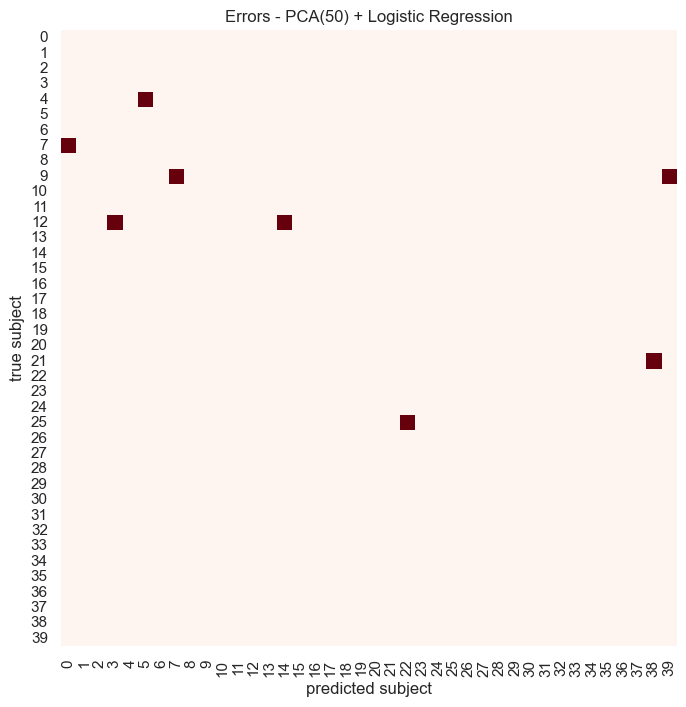

In [23]:
cm = confusion_matrix(y, y_pred)
np.fill_diagonal(cm, 0)
plt.figure(figsize=(9, 8))
sns.heatmap(cm, cmap='Reds', cbar=False, square=True, xticklabels=1, yticklabels=1)
plt.xlabel('predicted subject'); 
plt.ylabel('true subject')
plt.title('Errors - PCA(50) + Logistic Regression')
plt.show()

The 8 errors are spread over 8 subjects. Every error is a different pair. But 19 and 21 are responsible for 2 errors each. But, in general, there is no group of people that the model systematically mixes up.

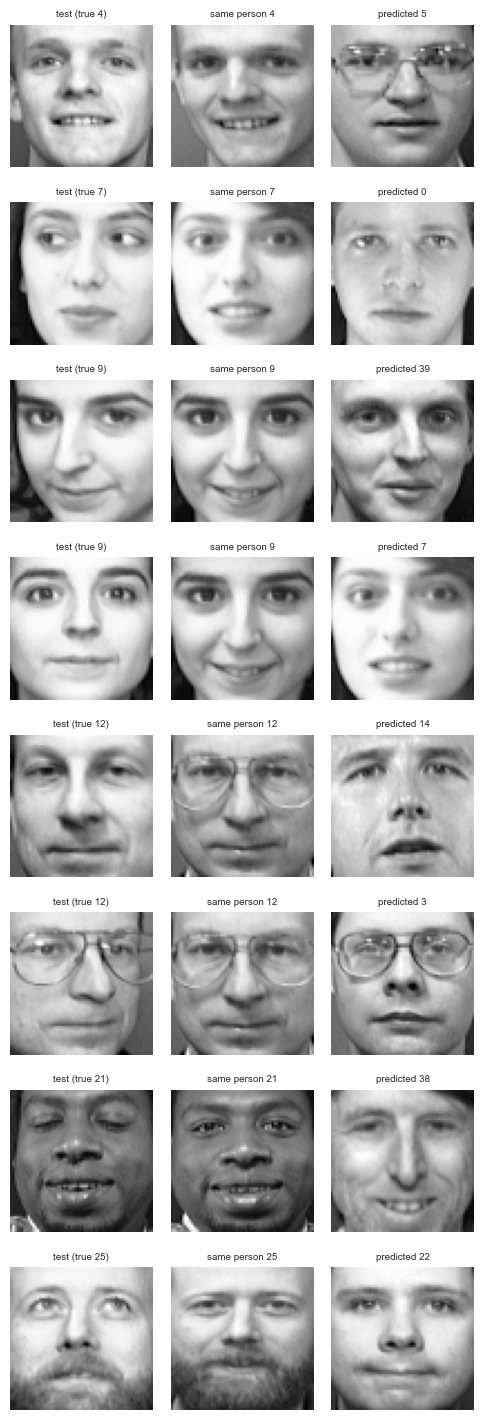

In [24]:
#ai
error_indices = np.where(wrong)[0]
fig, axes = plt.subplots(len(error_indices), 3, figsize=(5, 1.8 * len(error_indices)))
for row, i in enumerate(error_indices):
    true_s, pred_s = y[i], y_pred[i]
    same = [j for j in np.where(y == true_s)[0] if j != i][0]
    other = np.where(y == pred_s)[0][0]
    for col, (idx, title) in enumerate([(i, f'test (true {true_s})'),
                                        (same, f'same person {true_s}'),
                                        (other, f'predicted {pred_s}')]):
        axes[row, col].imshow(x[idx].reshape(64, 64), cmap='gray')
        axes[row, col].set_title(title, fontsize=7)
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

Looking at the misclassified photos next to another photo of the same person and the person the model predicted, some faces genuinely look alike. For example, person 25 was mistaken for person 22: they have similar lips and face shape; person 12 was mistaken for person 3: they ahve the same glasses on. In our opinion, it is the expression (person 21 - person 38), head position(e.g. person 9 - person 39), distinct facial features and lightning that matter most. But this is only a visual impression based on this 8 examples.

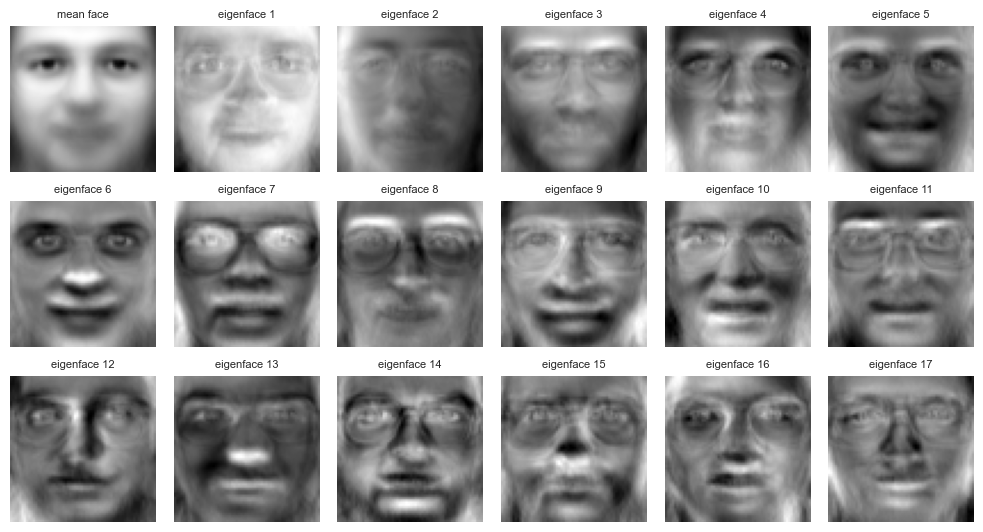

In [25]:
fig, axes = plt.subplots(3, 6, figsize=(10, 5.5))
axes[0, 0].imshow(pca_full.mean_.reshape(64, 64), cmap='gray')
axes[0, 0].set_title('mean face', fontsize=8)
for i, ax in enumerate(axes.ravel()[1:]):
    ax.imshow(pca_full.components_[i].reshape(64, 64), cmap='gray')
    ax.set_title(f'eigenface {i + 1}', fontsize=8)

for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

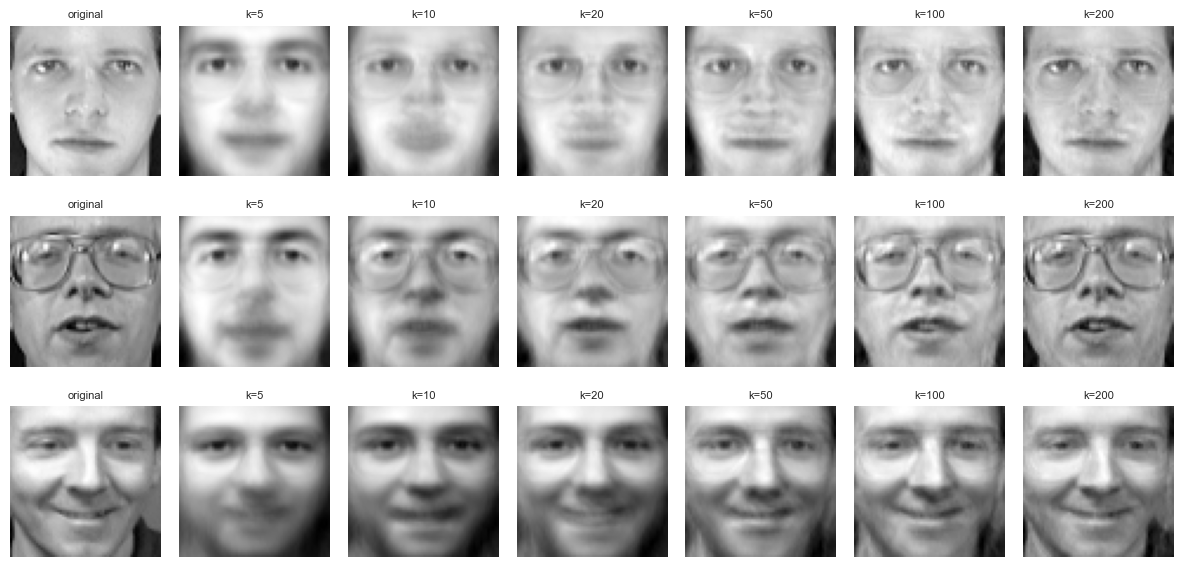

In [26]:
#ai
ks = [5, 10, 20, 50, 100, 200]
face_ids = [0, 10, 20]
z = pca_full.transform(x)

fig, axes = plt.subplots(len(face_ids), len(ks) + 1, figsize=(12, 2 * len(face_ids)))
for r, i in enumerate(face_ids):
    axes[r, 0].imshow(x[i].reshape(64, 64), cmap='gray')
    axes[r, 0].set_title('original', fontsize=8)
    for c, k in enumerate(ks, start=1):
        recon = pca_full.mean_ + z[i, :k] @ pca_full.components_[:k]
        axes[r, c].imshow(recon.reshape(64, 64), cmap='gray')
        axes[r, c].set_title(f'k={k}', fontsize=8)

for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

The mean face and the first eigenfaces describe broad patterns like headshape and lightning, later ones describe finer details. In the reconstructions, a face is already recognizable at about 50 components and further components add only small details. This agrees with 8.1, where accuracy stops improving at ~50 components. 

## 10 Limitations and Conclusions

### Conclusions

**Question:** how well can PCA (eigenfaces) + a simple classifier identify which of 40 people is in a face photo and how manycomponents are enough?

1. **Indetification works well**. PCA (50 components) + Logistic regressions reaches 0.980 +- 0.007 accuracy. PCA + kNN and PCA + SVM reach about 0.93-0.94.

2. **PCA loses almost nothing.** At 50 components the accuracy equals the same as on classifier on raw pixels (logistic regression 0.980 vs 0.980, kNN 0.930 vs 0.933), while using about 80 times fewer features that the 4096 pixels.

3. **How many components are enough.** Acuracy rises quickly up to about 20-30 components and is flat from about 50. 50 components keep 87.4% of the variance, so the variance is not needed in full for identification.

4. **Model ranking.** Logistic Regression is better than kNN and SVM by about 4-5 points for k>=20, which is larger than its std. kNN and SVM can't be distincted from each other. 

5. **Errors.** The best model makes 8 errors out of 400 photos. In general, there is no group of people that the model systematically mixes up.

### Limitations
-**Small data.** There are only 10 photos per person, so each fold trains on 8 photos per person and tests on 2. The uncertainty is wide.

-**Error analysis is visual.** With 8 errors, the patterns are just visual impression and not tested causes.

-**Uniform ondtions.** All photots are frontal, cropped, centered. In real conditions, the results would probably be worse.